# Evento Evaluativo 4 — Análisis de Datos (2026-2)
## Equipo 5: Predicción de incumplimiento financiero y análisis de perfiles de riesgo

**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009)
**Docente:** Daniel Alexis Nieto Mora · **Grupo:** 190304018-1

**Integrantes:**
- Juan Pablo Robledo (líder)
- María Camila Álvarez
- Duban Guerrero
- Andrés Villa

---
**Contenido**
1. Descripción del problema
2. Comprensión y exploración de los datos (EDA)
3. Preprocesamiento
4. Componente supervisado
5. Componente no supervisado
6. Visualización y reducción de dimensionalidad
7. Análisis comparativo supervisado vs. no supervisado
8. Conclusiones y recomendaciones

## 1. Descripción del problema

Un banco de Taiwán registró, para 30.000 clientes de tarjeta de crédito, su cupo, datos demográficos y seis meses (abril–septiembre de 2005) de **estado de pago**, **monto facturado** y **monto pagado**. La variable objetivo indica si el cliente **incumplió el pago en el mes siguiente** (octubre de 2005).

**Objetivos**
- **Supervisado:** estimar la probabilidad de que un cliente incumpla en el próximo periodo y clasificarlo como riesgoso / no riesgoso.
- **No supervisado:** descubrir, *sin usar la etiqueta*, segmentos de clientes con comportamientos financieros similares (patrones de pago, uso del cupo) y contrastarlos después con el incumplimiento real.

**Preguntas que guían el análisis**
1. ¿Qué tan desbalanceada está la variable objetivo y cómo afecta el modelado?
2. ¿Qué capacidad predictiva tiene el historial de pagos frente a las variables financieras y demográficas?
3. ¿Qué modelo ofrece el mejor equilibrio entre *Recall* (detectar morosos) y *Precision* (no castigar buenos clientes)?
4. ¿Existen segmentos naturales de clientes y se relacionan con el riesgo de incumplimiento?
5. ¿Qué riesgos (éticos, regulatorios, técnicos) implica usar estos modelos en decisiones de crédito?

In [1]:
import warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Rutas: funciona si el notebook se ejecuta desde la raíz o desde /notebooks
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR = BASE / "data", BASE / "figuras"
DATA_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

def guardar(nombre):
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight", dpi=130)

## 2. Comprensión y exploración de los datos

### 2.1 Carga
Si el archivo no está en `data/`, se descarga del repositorio de UCI.

In [2]:
ARCHIVO = DATA_DIR / "default of credit card clients.xls"
if not ARCHIVO.exists():
    import urllib.request, zipfile, io
    url = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(DATA_DIR)

raw = pd.read_excel(ARCHIVO, header=1)          # la fila 0 contiene X1..X23
print("Dimensiones:", raw.shape)
raw.head()

Dimensiones: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 2.2 Diccionario de variables

| Variable | Descripción |
|---|---|
| `LIMIT_BAL` | Cupo de crédito (dólares NT), incluye cupo individual y familiar |
| `SEX` | 1 = hombre, 2 = mujer |
| `EDUCATION` | 1 = posgrado, 2 = universidad, 3 = secundaria, 4 = otros (0, 5, 6 no documentados) |
| `MARRIAGE` | 1 = casado, 2 = soltero, 3 = otros (0 no documentado) |
| `AGE` | Edad en años |
| `PAY_0, PAY_2..PAY_6` | Estado de pago de sep. (PAY_0) a abr. (PAY_6): −2 sin consumo, −1 pagó total, 0 pago mínimo/revolvente, 1..9 meses de retraso |
| `BILL_AMT1..6` | Monto facturado sep. → abr. |
| `PAY_AMT1..6` | Monto pagado sep. → abr. |
| `default payment next month` | **Objetivo**: 1 = incumple en octubre |

Por claridad renombramos `PAY_0 → PAY_1` (así los sufijos 1..6 coinciden en las tres familias) y el objetivo a `DEFAULT`.

In [3]:
df = raw.rename(columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"}).drop(columns="ID")
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
CAT  = ["SEX", "EDUCATION", "MARRIAGE"]

print("Tipos de dato:\n", df.dtypes.value_counts(), "\n")
print("Valores faltantes totales:", int(df.isna().sum().sum()))
print("Filas duplicadas (sin ID):", int(df.duplicated().sum()))
df.describe().T.round(1)

Tipos de dato:
 int64    24
Name: count, dtype: int64 

Valores faltantes totales: 0
Filas duplicadas (sin ID): 35


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.3,129747.7,10000.0,50000.0,140000.0,240000.0,1000000.0
SEX,30000.0,1.6,0.5,1.0,1.0,2.0,2.0,2.0
EDUCATION,30000.0,1.9,0.8,0.0,1.0,2.0,2.0,6.0
MARRIAGE,30000.0,1.6,0.5,0.0,1.0,2.0,2.0,3.0
AGE,30000.0,35.5,9.2,21.0,28.0,34.0,41.0,79.0
PAY_1,30000.0,-0.0,1.1,-2.0,-1.0,0.0,0.0,8.0
PAY_2,30000.0,-0.1,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_3,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_4,30000.0,-0.2,1.2,-2.0,-1.0,0.0,0.0,8.0
PAY_5,30000.0,-0.3,1.1,-2.0,-1.0,0.0,0.0,8.0


### 2.3 Calidad de los datos
No hay valores nulos, pero sí **problemas de codificación** que funcionan como "faltantes disfrazados":

In [4]:
for c in ["EDUCATION", "MARRIAGE"]:
    print(c, df[c].value_counts().sort_index().to_dict())
print("PAY_1", df["PAY_1"].value_counts().sort_index().to_dict())
print("\nFacturas negativas (saldo a favor):", int((df[BILL] < 0).any(axis=1).sum()), "clientes")

EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_1 {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Facturas negativas (saldo a favor): 1930 clientes


- `EDUCATION` tiene 0, 5 y 6 (465 registros) y `MARRIAGE` tiene 0 (54) — categorías no documentadas. Se agrupan en "otros" (4 y 3 respectivamente). Es una regla fija, no aprendida de los datos, por lo que **no genera fuga de información**.
- `PAY_k` toma −2 y 0, no documentados en la descripción original; según el autor del dataset significan "sin consumo" y "pago revolvente (mínimo)". Se conservan como valores ordinales.
- Los montos facturados negativos representan saldo a favor del cliente: son válidos.
- Hay 35 filas duplicadas (sin `ID`): son clientes distintos con valores idénticos (en su mayoría inactivos), por lo que se conservan.

In [5]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"]  = df["MARRIAGE"].replace({0: 3})

### 2.4 Variable objetivo y desbalance

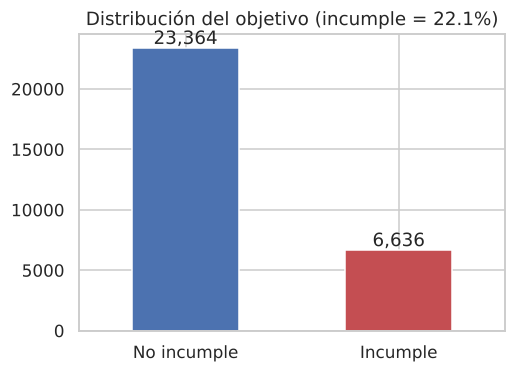

Razón de desbalance ≈ 3.5 : 1


In [6]:
tasa = df["DEFAULT"].mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
df["DEFAULT"].map({0: "No incumple", 1: "Incumple"}).value_counts().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title(f"Distribución del objetivo (incumple = {tasa:.1%})"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
for p in ax.patches: ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
guardar("01_objetivo"); plt.show()
print(f"Razón de desbalance ≈ {(1-tasa)/tasa:.1f} : 1")

El 22 % de los clientes incumple (≈ 3,5 : 1). Es un **desbalance moderado**: un modelo que siempre prediga "no incumple" tendría 78 % de *accuracy* y 0 % de *recall*, por eso evaluaremos con **Precision, Recall, F1, ROC-AUC y PR-AUC**, y trataremos el desbalance con pesos de clase y ajuste del umbral.

### 2.5 Variables demográficas

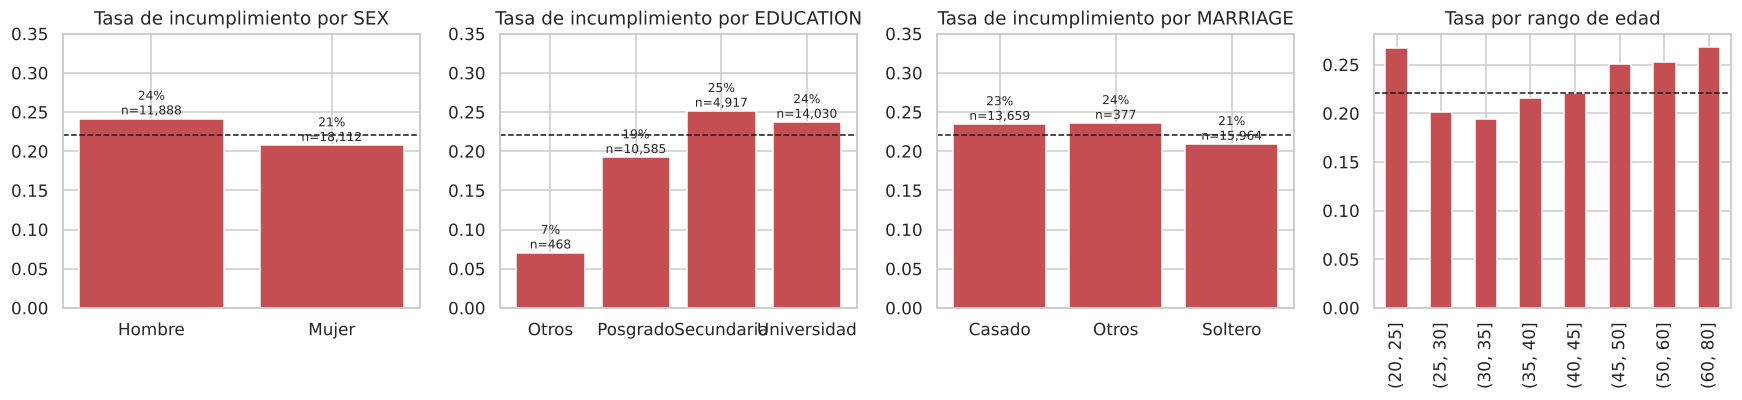

In [7]:
etiquetas = {"SEX": {1: "Hombre", 2: "Mujer"},
             "EDUCATION": {1: "Posgrado", 2: "Universidad", 3: "Secundaria", 4: "Otros"},
             "MARRIAGE": {1: "Casado", 2: "Soltero", 3: "Otros"}}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c in zip(axes[:3], CAT):
    t = df.groupby(df[c].map(etiquetas[c]))["DEFAULT"].agg(["mean", "size"])
    ax.bar(t.index, t["mean"], color="#C44E52")
    ax.axhline(tasa, ls="--", c="k", lw=1); ax.set_title(f"Tasa de incumplimiento por {c}")
    for i, (m, n) in enumerate(t.values): ax.text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0, .35)
edad = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 45, 50, 60, 80])
df.groupby(edad, observed=True)["DEFAULT"].mean().plot.bar(ax=axes[3], color="#C44E52")
axes[3].axhline(tasa, ls="--", c="k", lw=1); axes[3].set_title("Tasa por rango de edad"); axes[3].set_xlabel("")
plt.tight_layout(); guardar("02_demograficas"); plt.show()

Las diferencias demográficas existen pero son **pequeñas**: hombres 24 % vs. mujeres 21 %; secundaria 25 % vs. posgrado 19 %; y los extremos de edad (≤25 y >45 años) ≈ 25–27 % frente a ≈ 19–20 % entre 26 y 35 años. La categoría educativa "otros" tiene solo 7 %, pero agrupa códigos no documentados, así que no conviene sobreinterpretarla. Estas variables son además **sensibles** (sexo, edad, estado civil); volveremos a esto en la discusión de riesgos.

### 2.6 Historial de pagos (`PAY_k`)

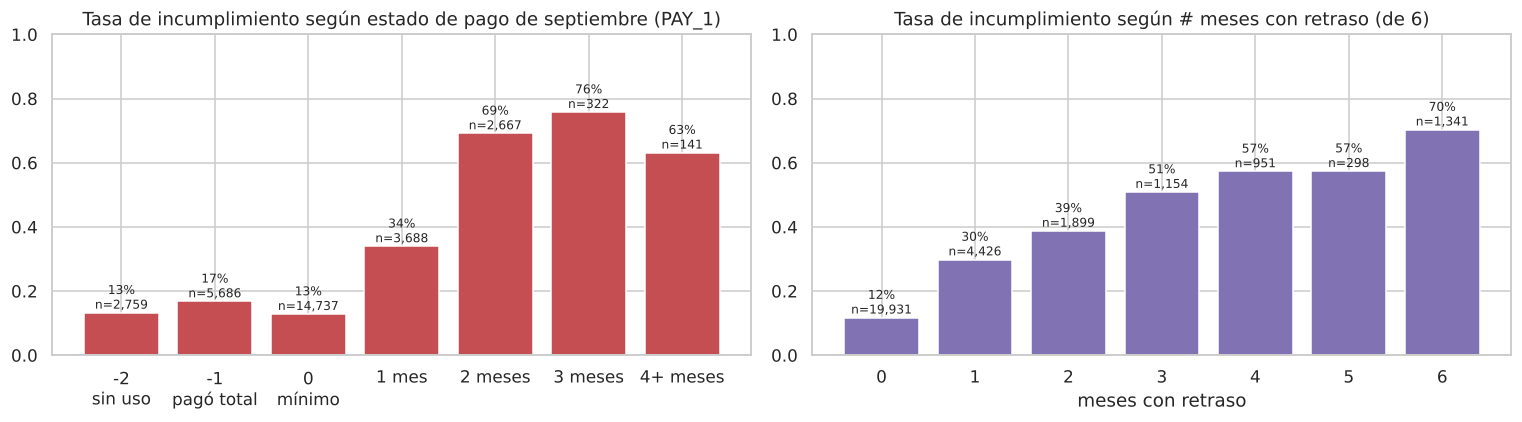

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
t = df.groupby(df["PAY_1"].clip(upper=4))["DEFAULT"].agg(["mean", "size"])
axes[0].bar(t.index.astype(str), t["mean"], color="#C44E52")
for i, (m, n) in enumerate(t.values): axes[0].text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(range(len(t))); axes[0].set_xticklabels(["-2\nsin uso", "-1\npagó total", "0\nmínimo", "1 mes", "2 meses", "3 meses", "4+ meses"])
axes[0].set_title("Tasa de incumplimiento según estado de pago de septiembre (PAY_1)"); axes[0].set_ylim(0, 1)

n_mora = (df[PAY] > 0).sum(axis=1)
t2 = df.groupby(n_mora)["DEFAULT"].agg(["mean", "size"])
axes[1].bar(t2.index, t2["mean"], color="#8172B3")
for i, (m, n) in zip(t2.index, t2.values): axes[1].text(i, m, f"{m:.0%}\nn={int(n):,}", ha="center", va="bottom", fontsize=8)
axes[1].set_title("Tasa de incumplimiento según # meses con retraso (de 6)"); axes[1].set_xlabel("meses con retraso"); axes[1].set_ylim(0, 1)
plt.tight_layout(); guardar("03_historial_pagos"); plt.show()

**Hallazgo clave del EDA:** el historial de pagos es, con diferencia, la señal más fuerte. Quien está al día en septiembre incumple ~13–17 %, quien tiene **2 meses de retraso incumple ~70 %**. La tasa también crece de forma casi monótona con el número de meses en mora. Esta relación es ordinal, por lo que conservaremos `PAY_k` como variables numéricas.

### 2.7 Variables financieras: cupo, facturación y pagos

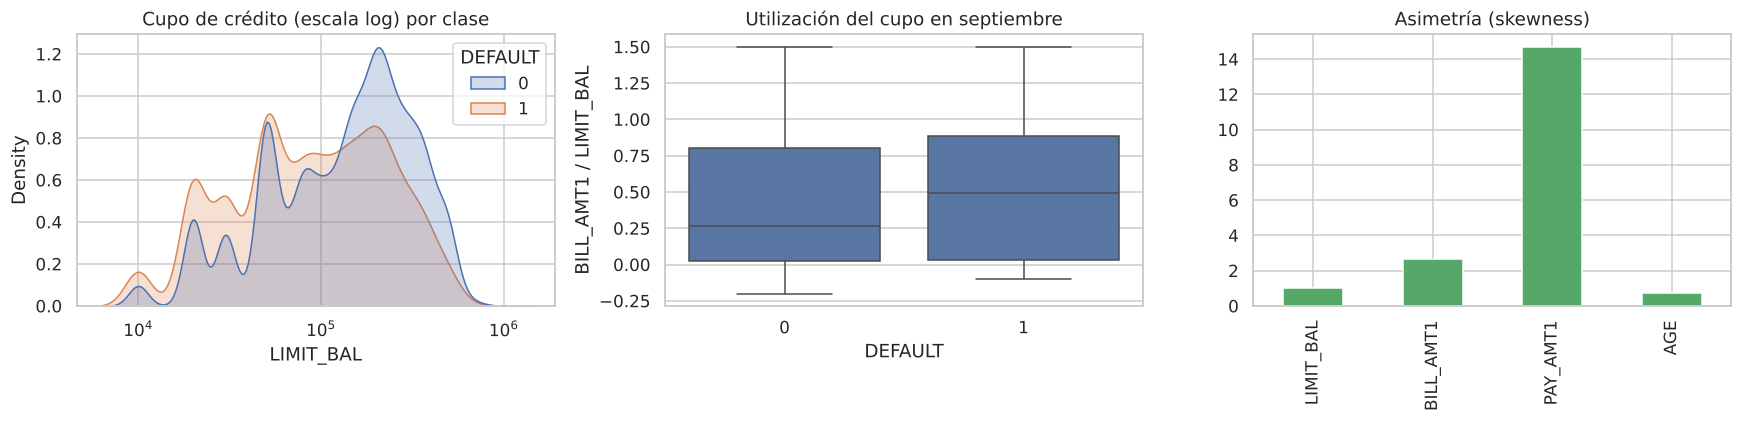

,LIMIT_BAL,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_AMT2
atípicos IQR,167,2400,2395,2745,2714


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.kdeplot(data=df, x="LIMIT_BAL", hue="DEFAULT", common_norm=False, fill=True, ax=axes[0], log_scale=True)
axes[0].set_title("Cupo de crédito (escala log) por clase")
sns.boxplot(x=df["DEFAULT"], y=(df["BILL_AMT1"] / df["LIMIT_BAL"]).clip(-0.2, 1.5), ax=axes[1])
axes[1].set_title("Utilización del cupo en septiembre"); axes[1].set_ylabel("BILL_AMT1 / LIMIT_BAL")
cols = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1", "AGE"]
(df[cols].skew()).plot.bar(ax=axes[2], color="#55A868"); axes[2].set_title("Asimetría (skewness)")
plt.tight_layout(); guardar("04_financieras"); plt.show()

def n_atipicos(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
pd.Series({c: n_atipicos(df[c]) for c in ["LIMIT_BAL"] + BILL[:2] + PAMT[:2]}, name="atípicos IQR").to_frame().T

- Los clientes que incumplen tienen **cupos más bajos** y **mayor utilización** del cupo.
- Los montos (facturas y pagos) son **muy asimétricos** y con miles de atípicos según el criterio IQR. No son errores: son clientes con cupos altos o pagos grandes. En lugar de eliminarlos aplicaremos una **transformación logarítmica con signo** (`sign(x)·log(1+|x|)`), que reduce su influencia en los modelos lineales y en las distancias del clustering.

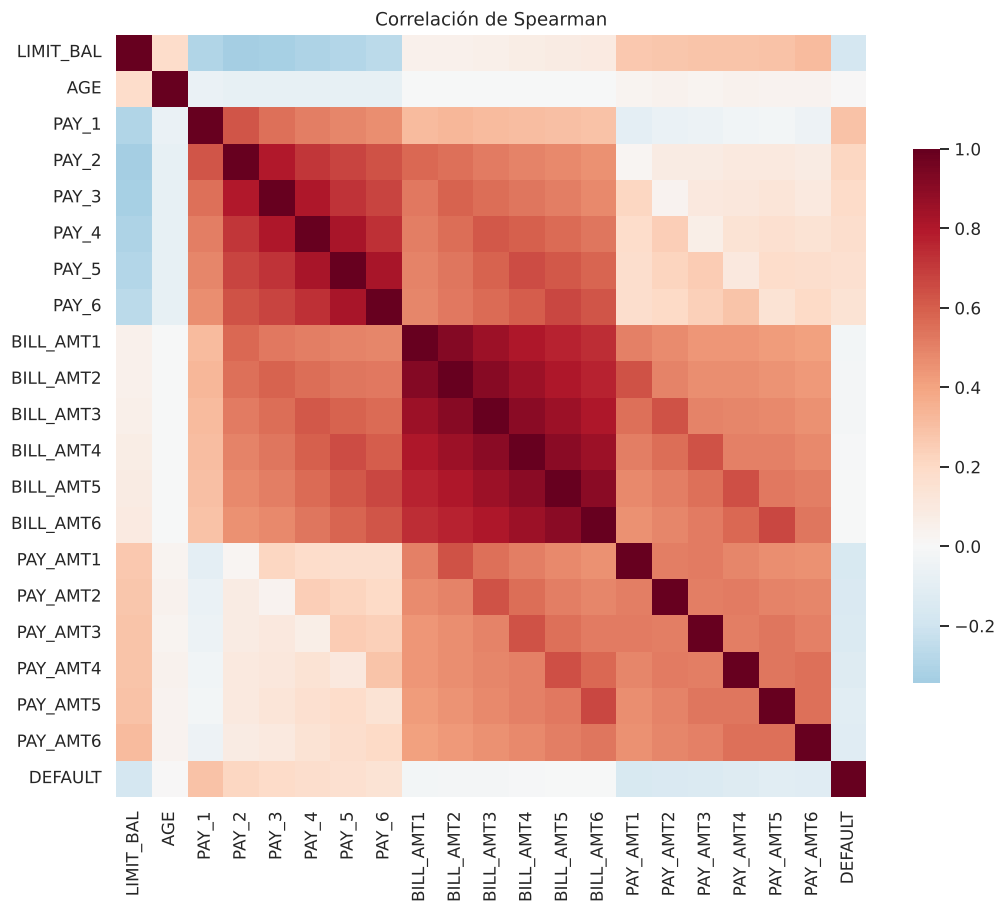

PAY_1        0.292
PAY_2        0.217
PAY_3        0.195
PAY_4        0.174
LIMIT_BAL   -0.170
PAY_AMT1    -0.160
PAY_5        0.159
PAY_AMT2    -0.151
Name: DEFAULT, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = df.drop(columns=CAT).corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlación de Spearman"); guardar("05_correlacion"); plt.show()
print(corr["DEFAULT"].drop("DEFAULT").sort_values(key=abs, ascending=False).head(8).round(3))

- `BILL_AMT1..6` están **casi perfectamente correlacionadas entre sí** (ρ > 0,9): hay mucha redundancia temporal. Lo mismo ocurre, en menor grado, con `PAY_1..6`.
- Las variables más correlacionadas con `DEFAULT` son los estados de pago, seguidas por el cupo (negativa).
- La multicolinealidad afecta la interpretación de coeficientes de la regresión logística (se usará regularización) pero no a los árboles.

## 3. Preprocesamiento

### 3.1 Ingeniería de características
Se crean variables **calculadas fila a fila** (no aprenden nada del conjunto, así que no hay fuga de información). Resumen el comportamiento de los seis meses en indicadores interpretables:

| Variable | Definición | Intuición |
|---|---|---|
| `n_meses_mora` | # meses con `PAY_k > 0` | persistencia de la mora |
| `max_mora` | máximo de `PAY_k` (mín. 0) | severidad de la mora |
| `meses_inactivo` | # meses con `PAY_k = −2` | tarjeta sin uso |
| `util_media`, `util_max` | `BILL_AMT_k / LIMIT_BAL` | presión sobre el cupo |
| `ratio_pago` | Σ pagos / Σ facturas del mes anterior (acotado a [0, 1]) | qué fracción de la deuda se paga |
| `tendencia_deuda` | (`BILL_AMT1` − `BILL_AMT6`) / `LIMIT_BAL` | la deuda crece o decrece |

In [11]:
def crear_variables(d):
    d = d.copy()
    d["n_meses_mora"]   = (d[PAY] > 0).sum(axis=1)
    d["max_mora"]       = d[PAY].max(axis=1).clip(lower=0)
    d["meses_inactivo"] = (d[PAY] == -2).sum(axis=1)
    util = d[BILL].div(d["LIMIT_BAL"], axis=0)
    d["util_media"] = util.mean(axis=1).clip(-0.5, 2)
    d["util_max"]   = util.max(axis=1).clip(-0.5, 2)
    # PAY_AMT_k paga la factura del mes anterior BILL_AMT_{k+1}
    pagado  = d[PAMT[:5]].sum(axis=1)
    debido  = d[BILL[1:]].clip(lower=0).sum(axis=1)
    d["ratio_pago"] = np.where(debido > 0, pagado / debido.replace(0, np.nan), 1.0)
    d["ratio_pago"] = d["ratio_pago"].clip(0, 1)
    d["tendencia_deuda"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-2, 2)
    return d

df = crear_variables(df)
NUEVAS = ["n_meses_mora", "max_mora", "meses_inactivo", "util_media", "util_max", "ratio_pago", "tendencia_deuda"]
df.groupby("DEFAULT")[NUEVAS].mean().T.round(3)

DEFAULT,0,1
n_meses_mora,0.504,1.996
max_mora,0.470,1.428
meses_inactivo,0.851,0.682
util_media,0.351,0.449
util_max,0.474,0.560
ratio_pago,0.408,0.310
tendencia_deuda,0.108,0.091


Las nuevas variables separan bien las clases: quienes incumplen tienen en promedio más meses en mora, mayor utilización y pagan una fracción menor de lo que deben.

### 3.2 Partición entrenamiento / prueba
Se separa **antes de cualquier transformación que aprenda de los datos**: 80 % entrenamiento, 20 % prueba, estratificado para conservar el 22 % de morosos en ambos conjuntos. El conjunto de prueba solo se usa al final.

In [12]:
X = df.drop(columns="DEFAULT")
y = df["DEFAULT"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, f"– tasa de incumplimiento {y_train.mean():.3f}")
print("Prueba:       ", X_test.shape,  f"– tasa de incumplimiento {y_test.mean():.3f}")

Entrenamiento: (24000, 30) – tasa de incumplimiento 0.221
Prueba:        (6000, 30) – tasa de incumplimiento 0.221


### 3.3 Pipeline de transformación (sin fuga de información)
Todo se encapsula en un `Pipeline` de scikit-learn, de modo que el escalador y el codificador **se ajustan solo con los pliegues de entrenamiento** dentro de la validación cruzada y luego se aplican a validación/prueba.

- **Montos** (`LIMIT_BAL`, `BILL_AMT*`, `PAY_AMT*`): log con signo + estandarización.
- **Ordinales y continuas** (`AGE`, `PAY_k`, variables creadas): estandarización.
- **Categóricas** (`SEX`, `EDUCATION`, `MARRIAGE`): *one-hot* (baja cardinalidad: 2–4 niveles), `handle_unknown="ignore"`.

La estandarización es necesaria para la regresión logística (regularización y convergencia); los modelos de árboles no la necesitan pero no los perjudica.

In [13]:
MONTOS = ["LIMIT_BAL"] + BILL + PAMT
OTRAS  = ["AGE"] + PAY + NUEVAS
log_signo = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")

preproceso = ColumnTransformer([
    ("montos", Pipeline([("log", log_signo), ("esc", StandardScaler())]), MONTOS),
    ("num",    StandardScaler(), OTRAS),
    ("cat",    OneHotEncoder(handle_unknown="ignore", drop="if_binary"), CAT),
])
FEATS = MONTOS + OTRAS + CAT
X_train, X_test = X_train[FEATS], X_test[FEATS]
print("Variables de entrada:", len(FEATS))

Variables de entrada: 30
